
# Factor Strategy Backtesting

## Objective

This notebook extends the factor strategy construction in Notebook 7 by implementing a more realistic historical backtest for three portfolios:

1. **Equal-weight benchmark:** allocates equally across the five stocks.
2. **Momentum strategy:** selects the two stocks with the strongest momentum signals.
3. **Low-volatility strategy:** selects the two stocks with the lowest trailing volatility estimates.

The backtest models monthly rebalancing, allows portfolio weights to drift between rebalancing dates, and includes a configurable transaction-cost assumption.

## Methodology

- Data source: Yahoo Finance through `yfinance`.
- Stock universe: Reliance Industries, TCS, Infosys, HDFC Bank, and ICICI Bank.
- Historical period: January 2020 to December 2025.
- Momentum signal: price 21 trading days ago divided by price 252 trading days ago, minus one.
- Low-volatility signal: standard deviation of the previous 63 daily returns.
- Rebalancing: monthly, with signals formed at month-end and executed on the next available trading day.
- Portfolio weights: long-only and fully invested.
- Transaction costs: configurable basis points per unit of one-way turnover.

**Timing convention:** a signal calculated using prices through a month-end date is not applied to the return on that same date. The target allocation is applied on the next available trading day. Portfolio weights drift as prices change and are reset only at the next scheduled rebalance.

This is a historical research exercise, not investment advice. Results depend on the selected stocks, dates, assumptions, and data quality.



## 1. Import Libraries and Set Parameters

The parameters below are defined centrally so that the backtest can be reproduced and modified without searching through multiple cells. The transaction-cost assumption is expressed in basis points (bps), where 1 basis point equals 0.01%.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Reproducible configuration
stocks = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS"
]

start_date = "2020-01-01"
end_date = "2026-01-01"  # Exclusive

momentum_lookback = 252
momentum_skip = 21
volatility_window = 63
number_selected = 2

trading_days_per_year = 252
annual_risk_free_rate = 0.0

# One-way transaction cost in basis points.
# Example: 10 bps = 0.10% of traded notional.
transaction_cost_bps = 10.0

print("Configuration loaded.")
print(f"Stocks: {len(stocks)}")
print(f"Period: {start_date} to {end_date} (end exclusive)")
print(f"Transaction cost: {transaction_cost_bps:.1f} bps per one-way turnover")


Configuration loaded.
Stocks: 5
Period: 2020-01-01 to 2026-01-01 (end exclusive)
Transaction cost: 10.0 bps per one-way turnover



## 2. Download and Prepare Price Data

We download adjusted closing prices for the selected stocks. With `auto_adjust=True`, the `Close` field is adjusted for corporate actions. Daily returns are calculated as simple percentage changes.

The analysis uses dates for which all five stocks have valid prices, so each portfolio comparison is based on a consistent stock universe.


In [2]:

raw_data = yf.download(
    stocks,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

if raw_data.empty:
    raise ValueError(
        "No data was downloaded. Check internet access, ticker symbols, and date range."
    )

# Handle yfinance's possible MultiIndex column formats
if isinstance(raw_data.columns, pd.MultiIndex):
    if "Close" in raw_data.columns.get_level_values(0):
        close_prices = raw_data["Close"]
    elif "Close" in raw_data.columns.get_level_values(1):
        close_prices = raw_data.xs("Close", axis=1, level=1)
    else:
        raise KeyError("Could not find the Close price field in downloaded data.")
else:
    if len(stocks) != 1:
        raise ValueError("Unexpected single-level data columns for a multi-stock download.")
    close_prices = raw_data[["Close"]].rename(columns={"Close": stocks[0]})

close_prices = close_prices.reindex(columns=stocks)
close_prices = close_prices.dropna(how="all")

# Use a common set of valid price dates for a consistent comparison.
close_prices = close_prices.dropna(subset=stocks, how="any")

if close_prices.empty or len(close_prices) <= momentum_lookback + 5:
    raise ValueError("Insufficient complete price data for the chosen lookback periods.")

daily_returns = close_prices.pct_change(fill_method=None)
daily_returns = daily_returns.dropna(how="any")

if daily_returns.empty:
    raise ValueError("Daily returns are empty after data cleaning.")

print(f"Price observations: {len(close_prices):,}")
print(f"Return observations: {len(daily_returns):,}")
print(f"First price date: {close_prices.index.min().date()}")
print(f"Last price date:  {close_prices.index.max().date()}")

display(close_prices.head())
display(daily_returns.describe().T)


Price observations: 1,487
Return observations: 1,486
First price date: 2020-01-01
Last price date:  2025-12-31


Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216125,1821.426880,619.740356,595.677185,514.797974
2020-01-02,683.660217,1813.065796,617.932068,599.474121,518.490479
2020-01-03,684.484070,1849.198486,627.436035,590.925293,516.812012
2020-01-06,668.609375,1849.030518,621.422485,578.136780,504.199829
2020-01-07,678.895630,1853.568481,612.212891,587.291382,501.514374


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
RELIANCE.NS,1486.0,0.000726,0.017810,-0.131539,-0.008392,0.000723,0.008513,0.147180
TCS.NS,1486.0,0.000464,0.014970,-0.094104,-0.006856,0.000064,0.007741,0.098451
INFY.NS,1486.0,0.000779,0.017263,-0.100393,-0.008452,0.000697,0.009621,0.120334
HDFCBANK.NS,1486.0,0.000463,0.016173,-0.126069,-0.007154,0.000586,0.007725,0.115996
ICICIBANK.NS,1486.0,0.000816,0.018717,-0.178478,-0.007192,0.000802,0.008726,0.137624



## 3. Construct Factor Signals and Monthly Targets

The momentum signal uses the price from 21 trading days ago relative to the price from 252 trading days ago. This approximates a 12-month lookback with the most recent month skipped.

The low-volatility signal is the rolling standard deviation of the previous 63 daily returns. At each month-end, the momentum strategy selects the two highest signals, while the low-volatility strategy selects the two lowest volatility estimates.

The target weights are scheduled for execution on the next available trading day. This avoids applying a signal to a return that occurred before the signal was available.


In [3]:

momentum_signal = (
    close_prices.shift(momentum_skip)
    / close_prices.shift(momentum_lookback)
    - 1.0
)

rolling_volatility = daily_returns.rolling(
    window=volatility_window,
    min_periods=volatility_window
).std()

# Month-end dates that are present in the cleaned return index
month_end_dates = (
    pd.Series(daily_returns.index, index=daily_returns.index)
    .groupby(daily_returns.index.to_period("M"))
    .last()
    .tolist()
)

# Map target allocations to the next available trading day
execution_targets = {
    "Equal-Weight": {},
    "Momentum": {},
    "Low-Volatility": {}
}

equal_target = pd.Series(1.0 / len(stocks), index=stocks)

for signal_date in month_end_dates:
    loc = daily_returns.index.get_indexer([signal_date])[0]
    if loc < 0 or loc + 1 >= len(daily_returns.index):
        continue

    execution_date = daily_returns.index[loc + 1]

    # Equal-weight target, reset monthly like the factor portfolios
    execution_targets["Equal-Weight"][execution_date] = equal_target.copy()

    mom = momentum_signal.loc[signal_date].dropna()
    vol = rolling_volatility.loc[signal_date].dropna()

    if len(mom) >= number_selected:
        selected = mom.nlargest(number_selected).index
        target = pd.Series(0.0, index=stocks)
        target.loc[selected] = 1.0 / number_selected
        execution_targets["Momentum"][execution_date] = target

    if len(vol) >= number_selected:
        selected = vol.nsmallest(number_selected).index
        target = pd.Series(0.0, index=stocks)
        target.loc[selected] = 1.0 / number_selected
        execution_targets["Low-Volatility"][execution_date] = target

for strategy, targets in execution_targets.items():
    print(f"{strategy}: {len(targets)} scheduled target allocations")

# Show the latest scheduled target allocations
for strategy, targets in execution_targets.items():
    if targets:
        latest_date = max(targets)
        print(f"\n{strategy} target for {latest_date.date()}:")
        display(targets[latest_date].rename("Weight").to_frame())


Equal-Weight: 71 scheduled target allocations
Momentum: 59 scheduled target allocations
Low-Volatility: 68 scheduled target allocations

Equal-Weight target for 2025-12-01:


,Weight
RELIANCE.NS,0.2
TCS.NS,0.2
INFY.NS,0.2
HDFCBANK.NS,0.2
ICICIBANK.NS,0.2



Momentum target for 2025-12-01:


,Weight
RELIANCE.NS,0.5
TCS.NS,0.0
INFY.NS,0.0
HDFCBANK.NS,0.5
ICICIBANK.NS,0.0



Low-Volatility target for 2025-12-01:


,Weight
RELIANCE.NS,0.0
TCS.NS,0.0
INFY.NS,0.0
HDFCBANK.NS,0.5
ICICIBANK.NS,0.5



## 4. Run the Backtest with Turnover and Transaction Costs

At the start of each trading day, the backtest checks whether a new target allocation is scheduled. If so, the portfolio is rebalanced and turnover is calculated.

One-way turnover is defined as half the sum of the absolute changes in stock weights. The initial investment is treated as a full deployment of capital and is charged accordingly. Transaction costs are deducted from portfolio returns on the execution day.

Between rebalancing dates, holdings are allowed to drift with stock returns. This is more realistic than assuming the portfolio is reset to its target weights every day.

The cost model is intentionally simple. It does not separately model taxes, bid-ask spreads, market impact, or stock-specific liquidity.


In [4]:

def run_monthly_backtest(returns, targets_by_date, cost_bps=10.0):
    """Backtest one strategy with monthly target weights and weight drift."""
    cost_rate = cost_bps / 10_000.0
    target_dates = set(targets_by_date.keys())

    current_weights = None
    net_returns = []
    gross_returns = []
    turnover_series = []
    cost_series = []
    weights_history = []

    for date, asset_returns in returns.iterrows():
        turnover = 0.0
        transaction_cost = 0.0

        # Execute target weights before the day's returns are realized.
        if date in target_dates:
            target_weights = targets_by_date[date].reindex(returns.columns).astype(float)

            if current_weights is None:
                # Treat the initial allocation as deployment from cash.
                turnover = 1.0
            else:
                turnover = 0.5 * (target_weights - current_weights).abs().sum()

            transaction_cost = turnover * cost_rate
            current_weights = target_weights.copy()

        if current_weights is None:
            net_returns.append(np.nan)
            gross_returns.append(np.nan)
            turnover_series.append(turnover)
            cost_series.append(transaction_cost)
            weights_history.append(pd.Series(np.nan, index=returns.columns))
            continue

        # Use current holdings to calculate the day's gross portfolio return.
        gross_return = float((current_weights * asset_returns).sum())

        # Approximate transaction costs as a fraction of portfolio value.
        net_return = gross_return - transaction_cost

        gross_returns.append(gross_return)
        net_returns.append(net_return)
        turnover_series.append(turnover)
        cost_series.append(transaction_cost)
        weights_history.append(current_weights.copy())

        # Let holdings drift after the day's stock returns.
        denominator = 1.0 + gross_return
        if denominator <= 0:
            raise ValueError(f"Invalid portfolio value on {date.date()}.")

        current_weights = current_weights * (1.0 + asset_returns) / denominator
        current_weights = current_weights / current_weights.sum()

    index = returns.index
    result = pd.DataFrame({
        "Gross Return": gross_returns,
        "Net Return": net_returns,
        "Turnover": turnover_series,
        "Transaction Cost": cost_series
    }, index=index)

    weights_df = pd.DataFrame(weights_history, index=index)
    return result, weights_df


backtest_results = {}
weights_history = {}

for strategy, targets in execution_targets.items():
    results, weights = run_monthly_backtest(
        daily_returns,
        targets,
        cost_bps=transaction_cost_bps
    )
    backtest_results[strategy] = results
    weights_history[strategy] = weights

gross_portfolio_returns = pd.DataFrame({
    strategy: result["Gross Return"]
    for strategy, result in backtest_results.items()
})

net_portfolio_returns = pd.DataFrame({
    strategy: result["Net Return"]
    for strategy, result in backtest_results.items()
}).dropna(how="all")

turnover_table = pd.DataFrame({
    strategy: result["Turnover"]
    for strategy, result in backtest_results.items()
})

transaction_cost_table = pd.DataFrame({
    strategy: result["Transaction Cost"]
    for strategy, result in backtest_results.items()
})

print("Net daily portfolio returns:")
display(net_portfolio_returns.head())

print("Total one-way turnover across the evaluation period:")
display(turnover_table.sum().rename("Cumulative One-Way Turnover").to_frame())

print("Total transaction-cost drag (sum of daily cost fractions, approximate):")
display(transaction_cost_table.sum().rename("Cumulative Cost Fraction").to_frame())


Net daily portfolio returns:


,Equal-Weight,Momentum,Low-Volatility
Date,,,
2020-02-03,-0.013959,NaN,NaN
2020-02-04,0.023715,NaN,NaN
2020-02-05,0.011473,NaN,NaN
2020-02-06,-0.003596,NaN,NaN
2020-02-07,-0.002619,NaN,NaN


Total one-way turnover across the evaluation period:


,Cumulative One-Way Turnover
Equal-Weight,2.320788
Momentum,11.647639
Low-Volatility,19.046527


Total transaction-cost drag (sum of daily cost fractions, approximate):


,Cumulative Cost Fraction
Equal-Weight,0.002321
Momentum,0.011648
Low-Volatility,0.019047



## 5. Compare Cumulative Growth Before and After Costs

The gross portfolio return excludes modeled transaction costs. The net return deducts the configured cost at each rebalance. Comparing the two illustrates how trading activity can affect a strategy's results.

The equal-weight benchmark is rebalanced monthly using the same execution convention. This makes the comparison more consistent with the factor portfolios.


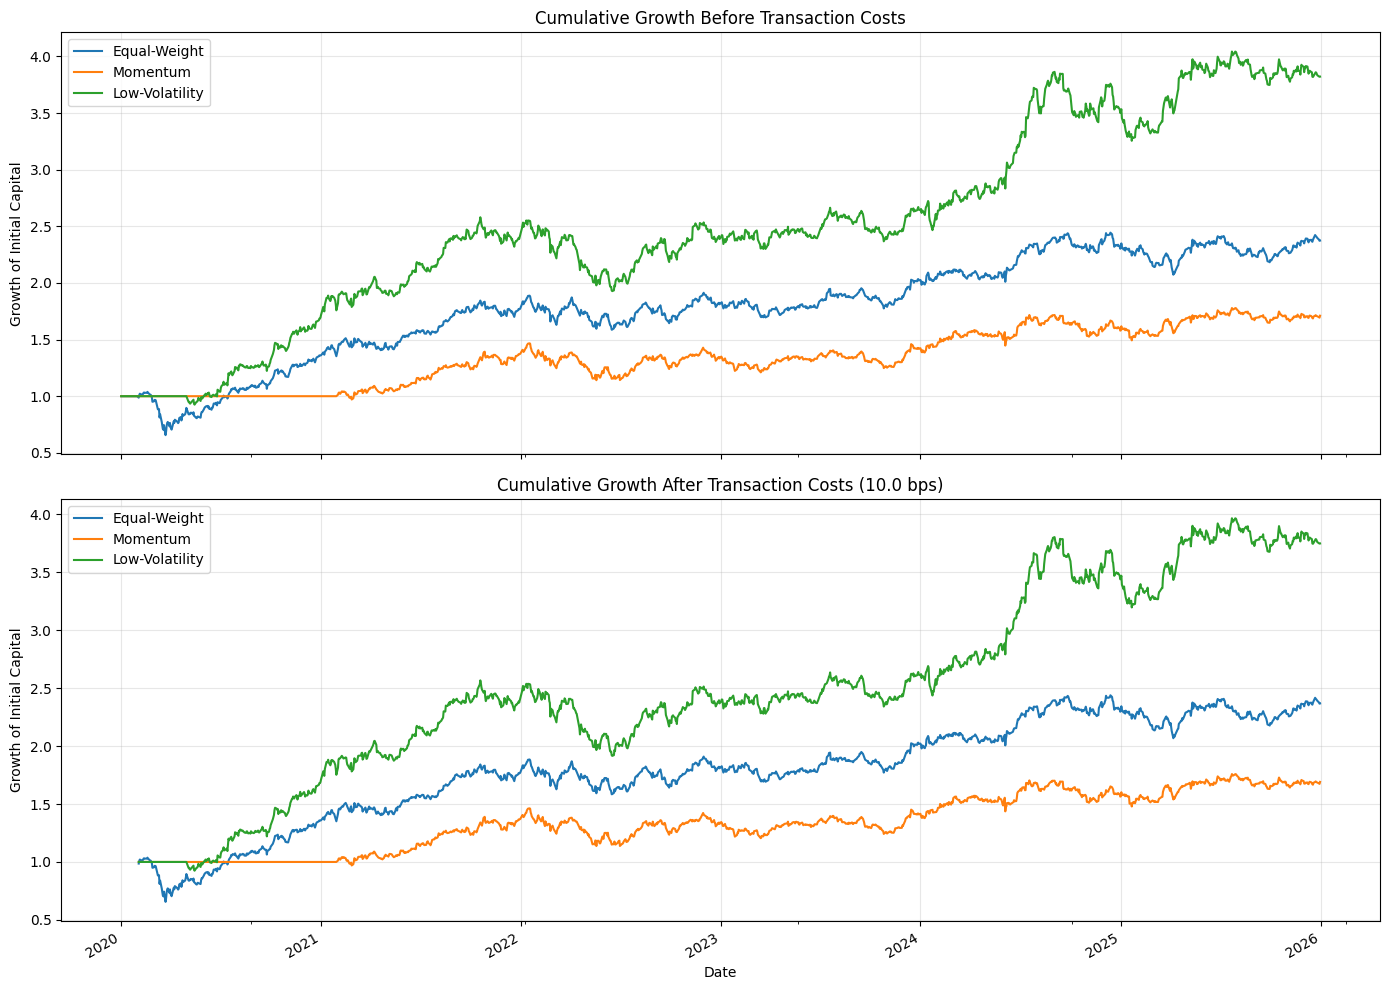

,Gross Cumulative Return (%),Net Cumulative Return (%)
Equal-Weight,137.37,136.81
Momentum,71.06,69.08
Low-Volatility,282.10,274.90


In [5]:

gross_growth = (1.0 + gross_portfolio_returns.fillna(0.0)).cumprod()
net_growth = (1.0 + net_portfolio_returns.fillna(0.0)).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

gross_growth.plot(ax=axes[0], title="Cumulative Growth Before Transaction Costs")
axes[0].set_ylabel("Growth of Initial Capital")
axes[0].grid(True, alpha=0.3)

net_growth.plot(ax=axes[1], title=f"Cumulative Growth After Transaction Costs ({transaction_cost_bps:.1f} bps)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Growth of Initial Capital")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gross_total_returns = gross_growth.iloc[-1] - 1.0
net_total_returns = net_growth.iloc[-1] - 1.0

growth_comparison = pd.DataFrame({
    "Gross Cumulative Return (%)": 100.0 * gross_total_returns,
    "Net Cumulative Return (%)": 100.0 * net_total_returns
})

display(growth_comparison.round(2))



## 6. Risk and Return Metrics

The following metrics are calculated from net daily returns after the modeled transaction costs. Annualized return is based on compounded growth over the observed number of daily returns. Annualized volatility uses the square root of 252 trading days.

The Sharpe ratio uses a zero annual risk-free-rate assumption. Maximum drawdown measures the deepest peak-to-trough decline in cumulative portfolio value.


,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal-Weight,1464,136.81%,16.00%,19.88%,0.847,-36.78%
Momentum,1216,69.08%,11.50%,17.16%,0.720,-22.25%
Low-Volatility,1406,274.90%,26.73%,18.81%,1.354,-25.38%


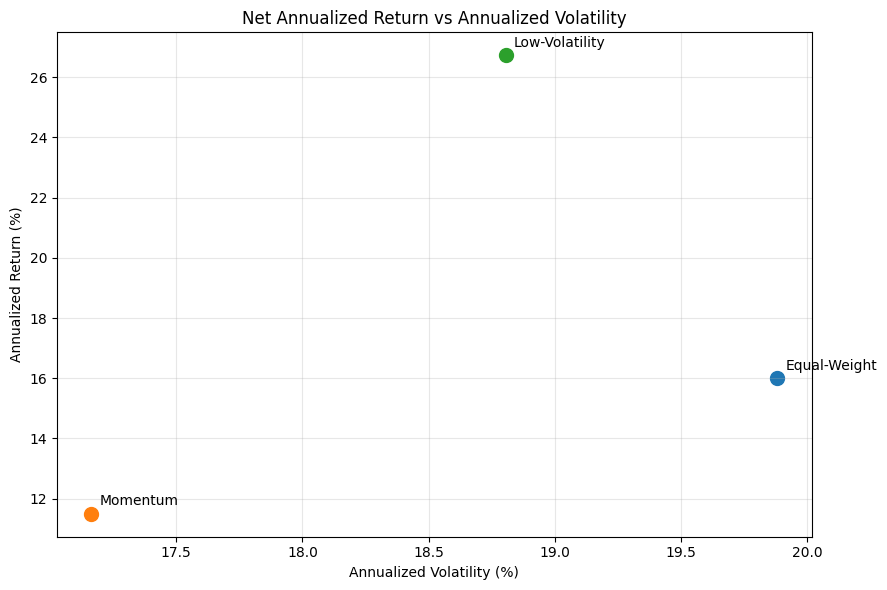

In [6]:

def calculate_metrics(returns, annual_rf=0.0, periods_per_year=252):
    returns = returns.dropna()
    if len(returns) < 2:
        return {
            "Observations": len(returns),
            "Cumulative Return": np.nan,
            "Annualized Return": np.nan,
            "Annualized Volatility": np.nan,
            "Sharpe Ratio": np.nan,
            "Maximum Drawdown": np.nan
        }

    wealth = (1.0 + returns).cumprod()
    cumulative_return = wealth.iloc[-1] - 1.0
    annualized_return = wealth.iloc[-1] ** (periods_per_year / len(returns)) - 1.0
    annualized_volatility = returns.std(ddof=1) * np.sqrt(periods_per_year)

    # Convert annual risk-free rate to an equivalent daily rate.
    daily_rf = (1.0 + annual_rf) ** (1.0 / periods_per_year) - 1.0
    excess_daily = returns - daily_rf
    sharpe = (
        excess_daily.mean() / returns.std(ddof=1) * np.sqrt(periods_per_year)
        if returns.std(ddof=1) > 0 else np.nan
    )

    drawdown = wealth / wealth.cummax() - 1.0

    return {
        "Observations": len(returns),
        "Cumulative Return": cumulative_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min()
    }


metric_table = pd.DataFrame({
    strategy: calculate_metrics(net_portfolio_returns[strategy], annual_risk_free_rate)
    for strategy in net_portfolio_returns.columns
}).T

display(metric_table.style.format({
    "Cumulative Return": "{:.2%}",
    "Annualized Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}",
    "Observations": "{:.0f}"
}))

# Plot annualized return versus annualized volatility
plt.figure(figsize=(9, 6))
for strategy, row in metric_table.iterrows():
    if pd.notna(row["Annualized Return"]) and pd.notna(row["Annualized Volatility"]):
        plt.scatter(row["Annualized Volatility"] * 100, row["Annualized Return"] * 100, s=100)
        plt.annotate(
            strategy,
            (row["Annualized Volatility"] * 100, row["Annualized Return"] * 100),
            xytext=(6, 6),
            textcoords="offset points"
        )

plt.title("Net Annualized Return vs Annualized Volatility")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 7. Out-of-Sample Evaluation

A strategy can appear successful because its rules happen to fit a particular historical period. To provide a simple robustness check, we split the available backtest period chronologically: the earlier 70% is the in-sample period, and the later 30% is the out-of-sample period.

The factor rules and parameters are fixed in advance in this notebook. The split is therefore a diagnostic rather than a guarantee against overfitting. The out-of-sample period should not be used to repeatedly tune the strategy and then reported as an untouched test set.


Chronological split date: 2024-07-15

In-sample metrics:


,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal-Weight,1099,130.42%,21.10%,21.58%,0.996,-36.78%
Momentum,851,68.21%,16.65%,18.06%,0.943,-22.25%
Low-Volatility,1041,241.10%,34.59%,19.76%,1.602,-25.38%



Out-of-sample metrics:


,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal-Weight,365,2.77%,1.91%,13.53%,0.207,-15.20%
Momentum,365,0.52%,0.36%,14.87%,0.098,-13.23%
Low-Volatility,365,9.91%,6.74%,15.73%,0.493,-15.96%


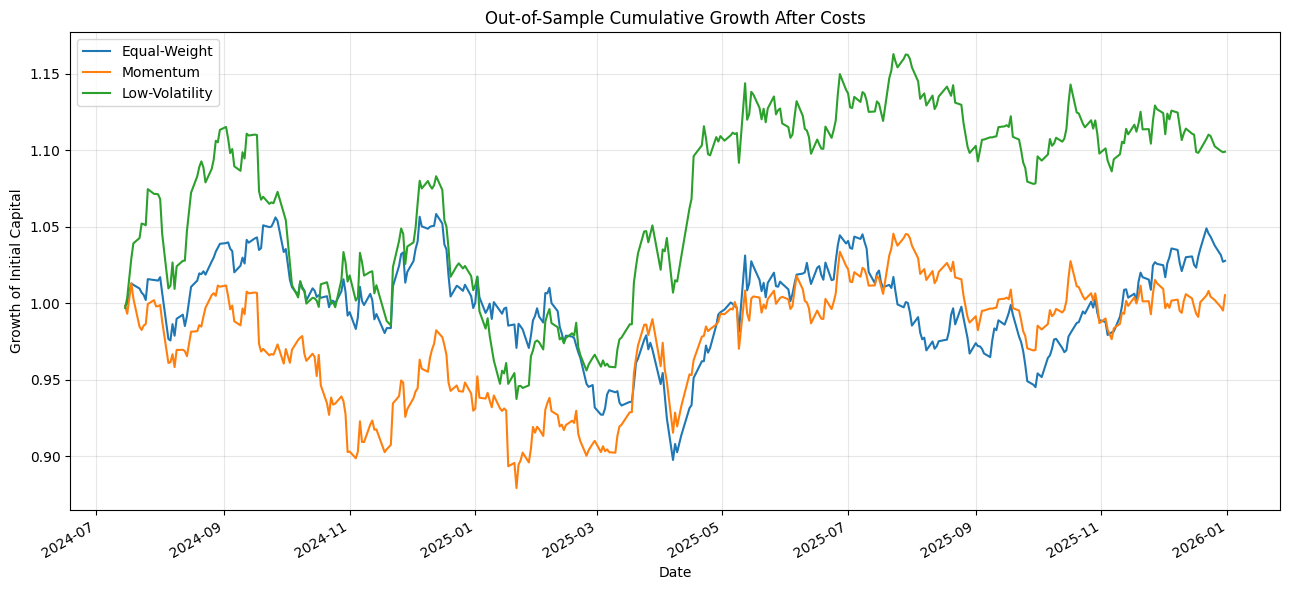

In [7]:

common_index = net_portfolio_returns.dropna(how="any").index

if len(common_index) < 100:
    print("Not enough common observations for a meaningful 70/30 split.")
else:
    split_position = int(len(common_index) * 0.70)
    split_date = common_index[split_position]

    in_sample = net_portfolio_returns.loc[net_portfolio_returns.index < split_date]
    out_sample = net_portfolio_returns.loc[net_portfolio_returns.index >= split_date]

    in_sample_metrics = pd.DataFrame({
        strategy: calculate_metrics(in_sample[strategy], annual_risk_free_rate)
        for strategy in in_sample.columns
    }).T

    out_sample_metrics = pd.DataFrame({
        strategy: calculate_metrics(out_sample[strategy], annual_risk_free_rate)
        for strategy in out_sample.columns
    }).T

    print(f"Chronological split date: {split_date.date()}")
    print("\nIn-sample metrics:")
    display(in_sample_metrics.style.format({
        "Cumulative Return": "{:.2%}",
        "Annualized Return": "{:.2%}",
        "Annualized Volatility": "{:.2%}",
        "Sharpe Ratio": "{:.3f}",
        "Maximum Drawdown": "{:.2%}",
        "Observations": "{:.0f}"
    }))

    print("\nOut-of-sample metrics:")
    display(out_sample_metrics.style.format({
        "Cumulative Return": "{:.2%}",
        "Annualized Return": "{:.2%}",
        "Annualized Volatility": "{:.2%}",
        "Sharpe Ratio": "{:.3f}",
        "Maximum Drawdown": "{:.2%}",
        "Observations": "{:.0f}"
    }))

    (1.0 + out_sample).cumprod().plot(
        figsize=(13, 6),
        title="Out-of-Sample Cumulative Growth After Costs"
    )
    plt.xlabel("Date")
    plt.ylabel("Growth of Initial Capital")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## 8. Turnover and Transaction-Cost Analysis

Turnover indicates how much the portfolio trades when its target allocation changes. A strategy with frequent or large allocation changes can experience a greater transaction-cost drag.

The cost assumption used here is a simple constant rate applied to one-way turnover. It is not a complete model of Indian equity trading costs. A more detailed implementation could separately account for brokerage, Securities Transaction Tax, exchange charges, GST, stamp duty, bid-ask spreads, and market impact.

The results should be tested under multiple cost assumptions before drawing conclusions about practical implementability.


In [8]:

turnover_summary = pd.DataFrame({
    "Total One-Way Turnover": turnover_table.sum(),
    "Average Daily Turnover": turnover_table.mean(),
    "Rebalance Events": [
        len(execution_targets[strategy])
        for strategy in turnover_table.columns
    ],
    "Approx. Total Cost Fraction": transaction_cost_table.sum()
})

display(turnover_summary.style.format({
    "Total One-Way Turnover": "{:.2f}",
    "Average Daily Turnover": "{:.4f}",
    "Approx. Total Cost Fraction": "{:.2%}"
}))

# Sensitivity analysis using the same gross returns and turnover series.
# This approximation applies the alternative cost rate to the recorded turnover.
cost_sensitivity = {}
for cost_bps in [0.0, 5.0, 10.0, 20.0, 30.0]:
    sensitivity_returns = {}
    for strategy in gross_portfolio_returns.columns:
        gross = gross_portfolio_returns[strategy]
        turnover = turnover_table[strategy]
        net = gross - turnover * (cost_bps / 10_000.0)
        sensitivity_returns[strategy] = net
    sensitivity_df = pd.DataFrame(sensitivity_returns).dropna(how="all")
    cost_sensitivity[f"{cost_bps:.0f} bps"] = {
        strategy: (1.0 + sensitivity_df[strategy].dropna()).prod() - 1.0
        for strategy in sensitivity_df.columns
    }

cost_sensitivity_table = pd.DataFrame(cost_sensitivity).T
cost_sensitivity_table.index.name = "One-Way Cost Assumption"
cost_sensitivity_table.columns.name = "Strategy"

print("Cumulative return sensitivity to transaction costs:")
display(cost_sensitivity_table.style.format("{:.2%}"))


,Total One-Way Turnover,Average Daily Turnover,Rebalance Events,Approx. Total Cost Fraction
Equal-Weight,2.32,0.0016,71,0.23%
Momentum,11.65,0.0078,59,1.16%
Low-Volatility,19.05,0.0128,68,1.90%


Cumulative return sensitivity to transaction costs:


Strategy,Equal-Weight,Momentum,Low-Volatility
One-Way Cost Assumption,,,
0 bps,137.37%,71.06%,282.10%
5 bps,137.09%,70.07%,278.49%
10 bps,136.81%,69.08%,274.90%
20 bps,136.26%,67.13%,267.84%
30 bps,135.71%,65.19%,260.90%



## 9. Summary and Limitations

This notebook compares an equal-weight benchmark with momentum and low-volatility strategies using monthly signal formation, next-trading-day execution, portfolio weight drift, turnover, and a configurable transaction-cost assumption.

Interpret the results cautiously:

- The universe contains only five large Indian stocks and is not representative of the full market.
- The backtest uses historical adjusted prices and assumes the selected stocks were available throughout the sample.
- The transaction-cost model is simplified and excludes detailed taxes, bid-ask spreads, and market impact.
- The out-of-sample split is a basic chronological diagnostic, not proof of robustness.
- Factor strategies can underperform and may be sensitive to parameter choices and market regimes.

A useful next step is to test the strategies across a broader, point-in-time stock universe, compare alternative rebalance frequencies and lookback periods, and document all assumptions before treating any result as evidence of a persistent investment effect.
